# Module 19 — Markov Decision Processes and Reinforcement Learning

This notebook is the runnable companion to the concept guide: read [README.md](README.md) first, or
keep it open alongside. Every section mirrors a numbered section of the guide. We compute discounted
returns, race ε-greedy against UCB1 and Thompson sampling on a bandit, solve a three-state MDP exactly
and by iteration, watch the Bellman operator contract, plan in a gridworld with value and policy
iteration, learn without a model (Monte Carlo, TD(0), SARSA, Q-learning), add linear function
approximation, derive and test the REINFORCE estimator with and without a baseline, and finish with a
numerical check of the closed-form optimal policy behind DPO and a picture of PPO's clipped objective.

Everything is plain NumPy — the environments are implemented here in a few dozen lines each.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4)
np.set_printoptions(precision=4, suppress=True)

## 1. Returns, discounting and the effective horizon

The return from time $t$ is $G_t = \sum_{k \ge 0} \gamma^k r_{t+k+1}$, and it obeys the recursion
$G_t = r_{t+1} + \gamma G_{t+1}$. The weights $\gamma^k$ sum to $1/(1-\gamma)$, the **effective horizon**;
a reward $k$ steps away counts for half its face value after $k = \ln 2 / \ln(1/\gamma)$ steps.
We compute the return of the reward sequence from the guide for several $\gamma$ and draw the weights.

In [2]:
def discounted_return(rewards, gamma):
    # G_0 = sum_k gamma^k r_{k+1}
    return float(sum(gamma**k * r for k, r in enumerate(rewards)))

def returns_backward(rewards, gamma):
    # all G_t at once via the recursion G_t = r_{t+1} + gamma G_{t+1}, run from the end
    G = np.zeros(len(rewards)); running = 0.0
    for t in reversed(range(len(rewards))):
        running = rewards[t] + gamma * running
        G[t] = running
    return G

rewards = [1, 0, 0, 4, 2]
for gamma in (0.5, 0.9, 0.99):
    G = returns_backward(rewards, gamma)
    print(f"gamma = {gamma:4.2f}: G_0 = {discounted_return(rewards, gamma):6.3f}   all G_t = {G}   "
          f"horizon 1/(1-gamma) = {1/(1-gamma):6.1f}   half-life = {np.log(2)/np.log(1/gamma):5.1f} steps")

print("\nweight gamma^k of a reward k steps ahead:")
print(f"{'k':>6s}" + "".join(f"{g:>10.2f}" for g in (0.5, 0.9, 0.99)))
for k in (1, 5, 10, 20, 50, 100, 200):
    print(f"{k:6d}" + "".join(f"{g**k:10.5f}" for g in (0.5, 0.9, 0.99)))

gamma = 0.50: G_0 =  1.625   all G_t = [1.625 1.25  2.5   5.    2.   ]   horizon 1/(1-gamma) =    2.0   half-life =   1.0 steps
gamma = 0.90: G_0 =  5.228   all G_t = [5.2282 4.698  5.22   5.8    2.    ]   horizon 1/(1-gamma) =   10.0   half-life =   6.6 steps
gamma = 0.99: G_0 =  6.802   all G_t = [6.8024 5.861  5.9202 5.98   2.    ]   horizon 1/(1-gamma) =  100.0   half-life =  69.0 steps

weight gamma^k of a reward k steps ahead:
     k      0.50      0.90      0.99
     1   0.50000   0.90000   0.99000
     5   0.03125   0.59049   0.95099
    10   0.00098   0.34868   0.90438
    20   0.00000   0.12158   0.81791
    50   0.00000   0.00515   0.60501
   100   0.00000   0.00003   0.36603
   200   0.00000   0.00000   0.13398


The reward of 4 at step four is worth $0.5$ at $\gamma = 0.5$ and $2.916$ at $\gamma = 0.9$: the two agents
are solving different problems. In the table, read down each column to the row $k = 1/(1-\gamma)$: the weight
has fallen to $\gamma^{1/(1-\gamma)} \approx 1/e \approx 0.37$ for every $\gamma$ close to 1, which is why
"$1/(1-\gamma)$ steps" is the right mental picture of how far an agent looks ahead.

## 2. Multi-armed bandits: ε-greedy, UCB1 and Thompson sampling

A 10-armed Bernoulli bandit with success probabilities drawn from $\text{Uniform}(0.1, 0.9)$ in each run.
Each algorithm is a *selection rule* that sees the pull counts $N_a$, the reward sums $S_a$ and the round
$t$:

* **ε-greedy**: random arm with probability $\varepsilon$, otherwise the best empirical mean;
* **optimistic initialisation**: greedy, with unseen arms valued at 1;
* **UCB1**: $\arg\max_a\, S_a/N_a + c\sqrt{\ln t / N_a}$ with $c = \sqrt 2$ (every arm is pulled once first);
* **Thompson sampling**: draw $\tilde\mu_a \sim \text{Beta}(1 + S_a,\, 1 + N_a - S_a)$ and pull the largest draw.

We record the per-step regret $\mu^* - \mu_{a_t}$ and whether the optimal arm was pulled, averaged over 20 runs.

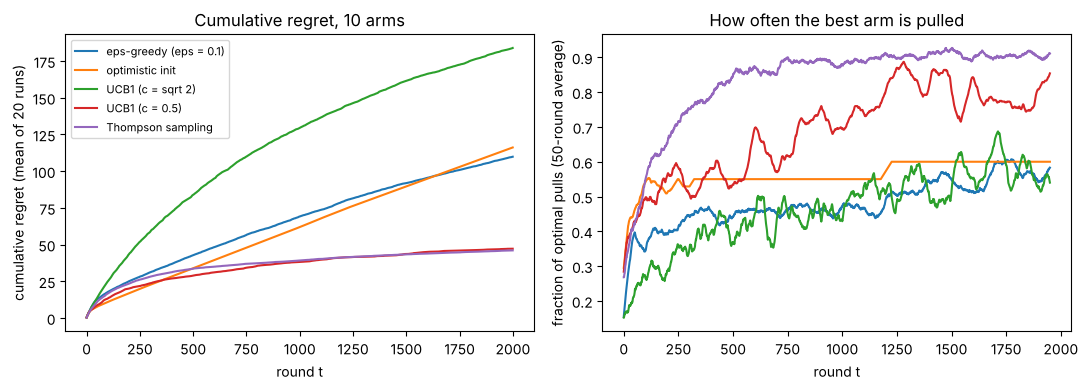

algorithm                   regret @ 400  regret @ 2000  optimal (last 200)
eps-greedy (eps = 0.1)              36.8          109.8               0.569
optimistic init                     28.3          116.1               0.600
UCB1 (c = sqrt 2)                   72.1          183.9               0.555
UCB1 (c = 0.5)                      26.9           47.2               0.791
Thompson sampling                   31.2           46.1               0.907


In [3]:
def argmax_random_tie(values, rng):
    return int(rng.choice(np.flatnonzero(values == values.max())))

def select_eps_greedy(N, S, t, rng, eps=0.1):
    if rng.random() < eps:
        return int(rng.integers(len(N)))
    means = np.where(N > 0, S / np.maximum(N, 1), 0.0)
    return argmax_random_tie(means, rng)

def select_optimistic(N, S, t, rng, init=1.0):
    means = np.where(N > 0, S / np.maximum(N, 1), init)      # unseen arms look as good as possible
    return argmax_random_tie(means, rng)

def select_ucb1(N, S, t, rng, c=np.sqrt(2)):
    if (N == 0).any():                                        # pull every arm once first
        return int(np.argmin(N))
    return int(np.argmax(S / N + c * np.sqrt(np.log(t) / N)))

def select_thompson(N, S, t, rng):
    return int(np.argmax(rng.beta(S + 1, N - S + 1)))         # Beta(1,1) prior, one posterior draw per arm

def run_bandit(select, probs, T, rng, **kw):
    n_arms = len(probs); N = np.zeros(n_arms); S = np.zeros(n_arms)
    regret = np.zeros(T); optimal = np.zeros(T); best = int(np.argmax(probs))
    for t in range(1, T + 1):
        a = select(N, S, t, rng, **kw)
        r = float(rng.random() < probs[a])
        N[a] += 1; S[a] += r
        regret[t - 1] = probs[best] - probs[a]; optimal[t - 1] = (a == best)
    return regret, optimal

def average_runs(select, n_runs=20, T=2000, n_arms=10, seed=0, **kw):
    rng_b = np.random.default_rng(seed)
    cum_regret = np.zeros((n_runs, T)); opt = np.zeros((n_runs, T))
    for run in range(n_runs):
        probs = rng_b.uniform(0.1, 0.9, size=n_arms)
        regret, optimal = run_bandit(select, probs, T, rng_b, **kw)
        cum_regret[run] = np.cumsum(regret); opt[run] = optimal
    return cum_regret.mean(axis=0), opt.mean(axis=0)

algorithms = {
    "eps-greedy (eps = 0.1)":  (select_eps_greedy, {}),
    "optimistic init":         (select_optimistic, {}),
    "UCB1 (c = sqrt 2)":       (select_ucb1, {}),
    "UCB1 (c = 0.5)":          (select_ucb1, {"c": 0.5}),
    "Thompson sampling":       (select_thompson, {}),
}
results = {name: average_runs(sel, **kw) for name, (sel, kw) in algorithms.items()}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for name, (cum_regret, frac_opt) in results.items():
    ax1.plot(cum_regret, label=name)
    ax2.plot(np.convolve(frac_opt, np.ones(50) / 50, mode="valid"), label=name)
ax1.set_xlabel("round t"); ax1.set_ylabel("cumulative regret (mean of 20 runs)"); ax1.set_title("Cumulative regret, 10 arms")
ax2.set_xlabel("round t"); ax2.set_ylabel("fraction of optimal pulls (50-round average)"); ax2.set_title("How often the best arm is pulled")
ax1.legend(fontsize=8); plt.tight_layout(); plt.show()

print(f"{'algorithm':26s} {'regret @ 400':>13s} {'regret @ 2000':>14s} {'optimal (last 200)':>19s}")
for name, (cum_regret, frac_opt) in results.items():
    print(f"{name:26s} {cum_regret[399]:13.1f} {cum_regret[-1]:14.1f} {frac_opt[-200:].mean():19.3f}")

ε-greedy's regret grows along a straight line: it keeps spending 10% of its pulls on random arms forever.
UCB1 with the textbook constant $\sqrt 2$ explores *too much* on this easy problem (its bonuses stay large
for a long time), while $c = 0.5$ and Thompson sampling bend over towards the logarithmic shape the theory
promises. Optimistic initialisation is excellent here but has no mechanism for revisiting an arm whose
early draws were unlucky — on a harder problem it can lock onto the wrong arm.

The guide's worked example: three arms, $t = 10$, $N = (5, 3, 2)$, successes $(3, 2, 1)$.

empirical means : [0.6    0.6667 0.5   ]
UCB1 bonuses    : [0.9597 1.239  1.5174]
UCB1 indices    : [1.5597 1.9056 2.0174]  -> pull arm 3 (the least-tried one)
Thompson pull probabilities: [0.3282 0.426  0.2458]
eps-greedy (eps = 0.1) pull probabilities: [0.0333 0.9333 0.0333]


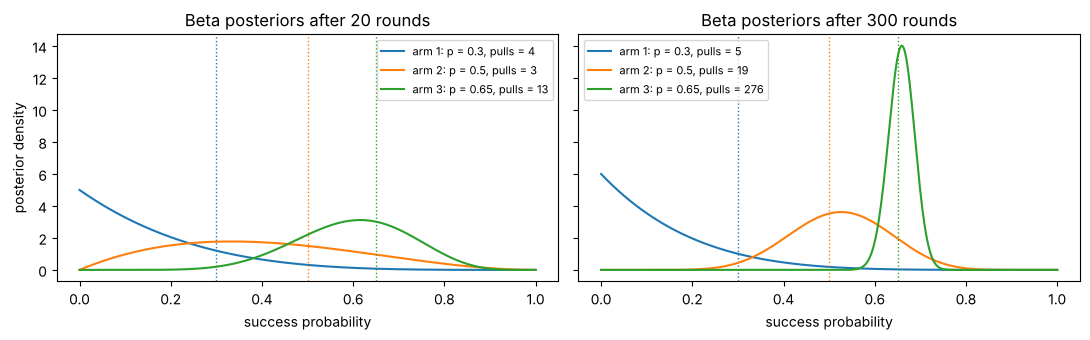

In [4]:
N = np.array([5., 3., 2.]); S = np.array([3., 2., 1.]); t = 10
means = S / N; bonus = np.sqrt(2 * np.log(t) / N)
print("empirical means :", means)
print("UCB1 bonuses    :", bonus)
print("UCB1 indices    :", means + bonus, " -> pull arm", int(np.argmax(means + bonus)) + 1, "(the least-tried one)")

# Thompson sampling pulls each arm with the posterior probability that it is the best
draws = rng.beta(S + 1, N - S + 1, size=(200_000, 3))
print("Thompson pull probabilities:", np.bincount(draws.argmax(axis=1), minlength=3) / len(draws))
print("eps-greedy (eps = 0.1) pull probabilities:", np.array([0.1/3, 0.9 + 0.1/3, 0.1/3]))

# the Beta posteriors Thompson sampling maintains, early and late in a 3-arm run
probs3 = np.array([0.3, 0.5, 0.65])
N3 = np.zeros(3); S3 = np.zeros(3); snapshots = {}
for step in range(1, 301):
    a = select_thompson(N3, S3, step, rng); r = float(rng.random() < probs3[a]); N3[a] += 1; S3[a] += r
    if step in (20, 300): snapshots[step] = (N3.copy(), S3.copy())
x = np.linspace(0, 1, 400)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, (step, (N3s, S3s)) in zip(axes, snapshots.items()):
    for a in range(3):
        ax.plot(x, stats.beta.pdf(x, S3s[a] + 1, N3s[a] - S3s[a] + 1), label=f"arm {a+1}: p = {probs3[a]}, pulls = {int(N3s[a])}")
        ax.axvline(probs3[a], color=f"C{a}", ls=":", lw=1)
    ax.set_title(f"Beta posteriors after {step} rounds"); ax.set_xlabel("success probability"); ax.legend(fontsize=8)
axes[0].set_ylabel("posterior density"); plt.tight_layout(); plt.show()

At $t = 10$ UCB1 pulls the arm with the *lowest* empirical mean, because it has been tried least and its
upper confidence bound is the highest; Thompson sampling still gives that arm about a quarter of the
pulls. After 300 rounds the posterior of the best arm is sharp and centred on $0.65$, while the posteriors
of the arms it stopped pulling stay wide — Thompson sampling only sharpens what it needs to know.

**Try it yourself:** set `eps=0.01` and `eps=0.3` in `average_runs(select_eps_greedy, eps=...)` and compare the
regret at 400 and at 2000 rounds — a small $\varepsilon$ is slow at first and good later, a large one the reverse.

### An adaptive clinical trial (Case study 1 of the guide)

Two treatments with true response rates $0.4$ and $0.6$, 200 patients. A fixed 1:1 design sends 100 patients to
each arm; Thompson sampling assigns each patient by posterior draws. We simulate 200 trials of each design and
measure two things: how many patients received the inferior treatment, and how often the trial ends with
$P(p_B > p_A \mid \text{data}) > 0.95$ — a proxy for its power to declare a winner.

fixed 1:1 : patients on the inferior arm A: mean  100.0 (sd   0.0, > 100 in 0% of trials)   responders: mean  100.1   P(B declared better at 95%): 0.89


thompson  : patients on the inferior arm A: mean   28.2 (sd  24.5, > 100 in 2% of trials)   responders: mean  114.1   P(B declared better at 95%): 0.74


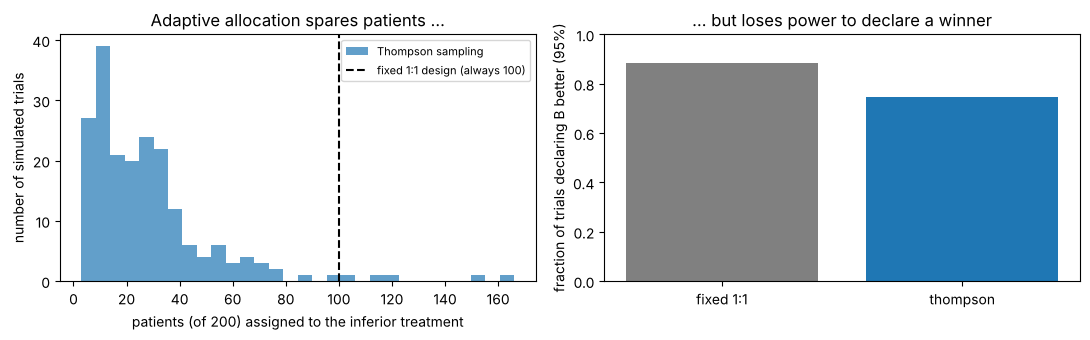

In [5]:
def run_trial(p_true, n_patients, method, rng):
    succ = np.zeros(2); fail = np.zeros(2); n_on_A = 0
    for i in range(n_patients):
        arm = int(np.argmax(rng.beta(succ + 1, fail + 1))) if method == "thompson" else i % 2
        response = rng.random() < p_true[arm]
        succ[arm] += response; fail[arm] += 1 - response; n_on_A += (arm == 0)
    return n_on_A, succ, fail

def posterior_prob_B_better(succ, fail, rng, n=20_000):
    return float(np.mean(rng.beta(succ[1] + 1, fail[1] + 1, n) > rng.beta(succ[0] + 1, fail[0] + 1, n)))

rng_t = np.random.default_rng(7)
summary = {}
for method in ("fixed 1:1", "thompson"):
    on_A, responders, declared = [], [], []
    for trial in range(200):
        n_on_A, succ, fail = run_trial((0.4, 0.6), 200, method, rng_t)
        on_A.append(n_on_A); responders.append(succ.sum()); declared.append(posterior_prob_B_better(succ, fail, rng_t) > 0.95)
    summary[method] = (np.array(on_A), np.array(responders), np.array(declared))
    print(f"{method:10s}: patients on the inferior arm A: mean {np.mean(on_A):6.1f} (sd {np.std(on_A):5.1f}, > 100 in {np.mean(np.array(on_A) > 100):.0%} of trials)   "
          f"responders: mean {np.mean(responders):6.1f}   P(B declared better at 95%): {np.mean(declared):.2f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
ax1.hist(summary["thompson"][0], bins=30, alpha=0.7, label="Thompson sampling")
ax1.axvline(100, color="k", ls="--", label="fixed 1:1 design (always 100)")
ax1.set_xlabel("patients (of 200) assigned to the inferior treatment"); ax1.set_ylabel("number of simulated trials")
ax1.set_title("Adaptive allocation spares patients ..."); ax1.legend(fontsize=8)
ax2.bar(["fixed 1:1", "thompson"], [summary[m][2].mean() for m in ("fixed 1:1", "thompson")], color=["gray", "C0"])
ax2.set_ylim(0, 1); ax2.set_ylabel("fraction of trials declaring B better (95%)"); ax2.set_title("... but loses power to declare a winner")
plt.tight_layout(); plt.show()

Thompson sampling sends on average only about 28 of the 200 patients (instead of 100) to the inferior arm and
produces about fourteen more responders per trial — but the probability of *declaring* B better at the 95% level
drops from about 0.89 to about 0.74, because the inferior arm's response rate is estimated from a few dozen
patients and its posterior stays wide. (The fixed design's 0.89 is what the usual power calculation predicts: a
difference of 0.2 with standard error $\sqrt{2 \cdot 0.24/100} \approx 0.069$ is 2.9 standard errors, and
$\Phi(2.9 - 1.645) \approx 0.89$.) Regret minimisation and hypothesis testing are different objectives; real adaptive designs cap the imbalance
or use a burn-in to buy back power.

## 3. A three-state MDP and exact policy evaluation

The guide's machine: states **G**ood, **W**orn, **B**roken; actions **run** (0) and **service** (1); $\gamma = 0.8$.
We store the model as arrays `P[s, a, s']` and `R[s, a]`. For a deterministic policy $\pi$ the Bellman expectation
equation is linear,

$$V^\pi = R^\pi + \gamma P^\pi V^\pi \quad\Longrightarrow\quad V^\pi = (I - \gamma P^\pi)^{-1} R^\pi,$$

and $Q^\pi(s, a) = R(s, a) + \gamma \sum_{s'} P(s' \mid s, a)\, V^\pi(s')$ tells us where a different action would do better.

In [6]:
STATES = ["Good", "Worn", "Broken"]; ACTS = ["run", "service"]
P_M = np.zeros((3, 2, 3))                       # P_M[s, a, s']
P_M[0, 0] = [0.75, 0.25, 0.0]                   # run in Good:   stays good or wears
P_M[1, 0] = [0.0, 0.5, 0.5]                     # run in Worn:   stays worn or breaks
P_M[2, 0] = [0.0, 0.0, 1.0]                     # run in Broken: stays broken
P_M[:, 1] = [1.0, 0.0, 0.0]                     # service from anywhere -> Good
R_M = np.array([[10., -2.], [6., -2.], [0., -12.]])   # R_M[s, a]
GAMMA_M = 0.8
assert np.allclose(P_M.sum(axis=2), 1.0)

def policy_evaluation_exact(P, R, policy, gamma):
    # policy: array of action indices, one per state
    S = P.shape[0]; idx = np.arange(S)
    P_pi = P[idx, policy]                       # rows P(. | s, pi(s))
    R_pi = R[idx, policy]
    return np.linalg.solve(np.eye(S) - gamma * P_pi, R_pi)

def q_from_v(P, R, V, gamma):
    return R + gamma * np.einsum("sat,t->sa", P, V)

pi_run = np.array([0, 0, 0])
V_run = policy_evaluation_exact(P_M, R_M, pi_run, GAMMA_M)
print("I - gamma P^pi for 'always run':\n", np.eye(3) - GAMMA_M * P_M[np.arange(3), pi_run])
print("V^pi (always run) =", V_run)
Q_run = q_from_v(P_M, R_M, V_run, GAMMA_M)
print("\nQ^pi(s, a) under 'always run':")
for s in range(3):
    print(f"  {STATES[s]:7s} run {Q_run[s, 0]:6.2f}   service {Q_run[s, 1]:6.2f}   -> greedy: {ACTS[int(Q_run[s].argmax())]}")

I - gamma P^pi for 'always run':
 [[ 0.4 -0.2  0. ]
 [ 0.   0.6 -0.4]
 [ 0.   0.   0.2]]
V^pi (always run) = [30. 10.  0.]

Q^pi(s, a) under 'always run':
  Good    run  30.00   service  22.00   -> greedy: run
  Worn    run  10.00   service  22.00   -> greedy: service
  Broken  run   0.00   service  12.00   -> greedy: service


Exactly the hand computation of the guide: $V_B = 0$, $V_W = 10$, $V_G = 30$. Servicing from any state leads
to Good (worth 30), so it beats running in **Worn** ($22 > 10$) and in **Broken** ($12 > 0$) but not in **Good**
($22 < 30$). The greedy policy with respect to $Q^{\pi}$ is therefore (run, service, service) — Section 5 shows
that this one improvement step already reaches the optimum.

## 4. Bellman operators are $\gamma$-contractions

Iterating $V \leftarrow R^\pi + \gamma P^\pi V$ converges to $V^\pi$, and iterating the optimality operator
$(TV)(s) = \max_a [R(s,a) + \gamma \sum_{s'} P(s' \mid s,a) V(s')]$ converges to $V^*$, in both cases because
$\lVert TU - TV\rVert_\infty \le \gamma\, \lVert U - V\rVert_\infty$. We check the contraction on random pairs of value
vectors and watch the error shrink by a factor $\gamma$ per sweep.

max over 1000 random pairs of ||TU - TV|| / ||U - V|| = 0.8000  (gamma = 0.8)
V* = [40. 30. 20.], optimal policy = ['run', 'service', 'service'], sweeps to 1e-10: 113
  sweep 0: V_k = [0. 0. 0.], error 40.0000
  sweep 1: V_k = [10.  6.  0.], error 30.0000
  sweep 2: V_k = [17.2  8.4  0. ], error 22.8000
  sweep 3: V_k = [22.   11.76  1.76], error 18.2400


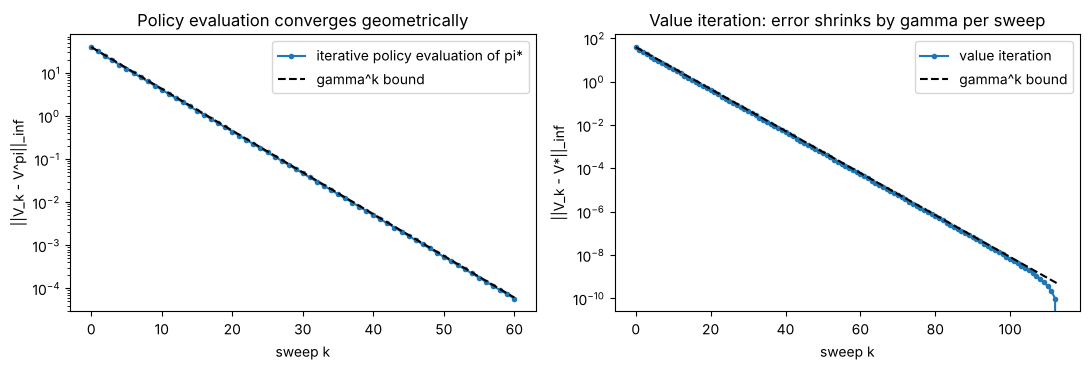

stopping when successive sweeps differ by < 0.001: sweep 41, true error 3.75e-03, guaranteed bound eps*gamma/(1-gamma) = 4.00e-03


In [7]:
def bellman_optimality_operator(V, P, R, gamma):
    return q_from_v(P, R, V, gamma).max(axis=1)

def value_iteration(P, R, gamma, tol=1e-10, max_iter=100_000):
    V = np.zeros(P.shape[0]); history = [V.copy()]
    for k in range(max_iter):
        V_new = bellman_optimality_operator(V, P, R, gamma)
        history.append(V_new.copy())
        if np.abs(V_new - V).max() < tol:
            return V_new, q_from_v(P, R, V_new, gamma).argmax(axis=1), history
        V = V_new
    return V, q_from_v(P, R, V, gamma).argmax(axis=1), history

# (a) contraction check on random value vectors
ratios = []
for _ in range(1000):
    U, V = rng.normal(size=3) * 50, rng.normal(size=3) * 50
    TU, TV = bellman_optimality_operator(U, P_M, R_M, GAMMA_M), bellman_optimality_operator(V, P_M, R_M, GAMMA_M)
    ratios.append(np.abs(TU - TV).max() / np.abs(U - V).max())
print(f"max over 1000 random pairs of ||TU - TV|| / ||U - V|| = {max(ratios):.4f}  (gamma = {GAMMA_M})")

# (b) value iteration and iterative policy evaluation, error per sweep
V_star, pi_star, hist = value_iteration(P_M, R_M, GAMMA_M)
print(f"V* = {V_star}, optimal policy = {[ACTS[a] for a in pi_star]}, sweeps to 1e-10: {len(hist) - 1}")
err_vi = np.array([np.abs(h - V_star).max() for h in hist])
for k in range(4):
    print(f"  sweep {k}: V_k = {hist[k]}, error {err_vi[k]:.4f}")

V_pi1 = policy_evaluation_exact(P_M, R_M, pi_star, GAMMA_M)
V = np.zeros(3); err_pe = [np.abs(V - V_pi1).max()]
for k in range(60):
    V = R_M[np.arange(3), pi_star] + GAMMA_M * P_M[np.arange(3), pi_star] @ V
    err_pe.append(np.abs(V - V_pi1).max())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.semilogy(err_pe, "o-", ms=3, label="iterative policy evaluation of pi*")
ax1.semilogy(err_pe[0] * GAMMA_M ** np.arange(len(err_pe)), "k--", label="gamma^k bound")
ax1.set_xlabel("sweep k"); ax1.set_ylabel("||V_k - V^pi||_inf"); ax1.set_title("Policy evaluation converges geometrically"); ax1.legend()
ax2.semilogy(err_vi, "o-", ms=3, label="value iteration")
ax2.semilogy(err_vi[0] * GAMMA_M ** np.arange(len(err_vi)), "k--", label="gamma^k bound")
ax2.set_xlabel("sweep k"); ax2.set_ylabel("||V_k - V*||_inf"); ax2.set_title("Value iteration: error shrinks by gamma per sweep"); ax2.legend()
plt.tight_layout(); plt.show()

eps_stop = 1e-3; k_stop = next(k for k in range(1, len(hist)) if np.abs(hist[k] - hist[k-1]).max() < eps_stop)
print(f"stopping when successive sweeps differ by < {eps_stop}: sweep {k_stop}, true error {err_vi[k_stop]:.2e}, "
      f"guaranteed bound eps*gamma/(1-gamma) = {eps_stop*GAMMA_M/(1-GAMMA_M):.2e}")

No pair of value vectors is ever pushed apart by more than the factor $\gamma = 0.8$, and both error curves
run parallel to the dashed $\gamma^k$ line on the log scale — a straight line of slope $\log\gamma$. The
stopping rule "successive sweeps differ by less than $\epsilon$" certifies an error of at most
$\epsilon\gamma/(1-\gamma) = 4\epsilon$ here; with $\gamma = 0.99$ the same rule would only certify $99\epsilon$.

**Try it yourself:** set `GAMMA_M = 0.95` in Section 3 and re-run — how many sweeps does value iteration need,
and does the optimal policy change? (At $\gamma = 0.3$ it does: the myopic operator never services at all.)

## 5. Planning in a gridworld: value iteration and policy iteration

A $5 \times 5$ gridworld with walls, one pit and *slippery* moves: with probability 0.2 the agent moves
perpendicular to the intended direction (0.1 each way). Entering the goal gives $+10$, the pit $-10$, every
other move $-1$; goal and pit are terminal. The class below builds the full model `P[s, a, s']`, `R[s, a]`
so that we can plan exactly, and also offers a sampling `step` for the model-free methods later.

value iteration: 38 sweeps to tolerance 1e-10
V* on the grid:
 [[ 2.8621  4.8446  6.9064  9.5122  0.    ]
 [ 1.2936  0.      4.8446  0.      9.5122]
 [-0.0837  0.      1.7452  0.      5.4382]
 [-1.279  -1.1512  0.1681  0.      3.5555]
 [-2.2961 -1.8732 -0.8347  0.3129  1.7452]]
greedy policy:
 [['>' '>' '>' '>' '^']
 ['^' '^' '^' '^' '^']
 ['^' '^' '^' '^' '^']
 ['^' '>' '^' '^' '^']
 ['^' '>' '>' '>' '^']]


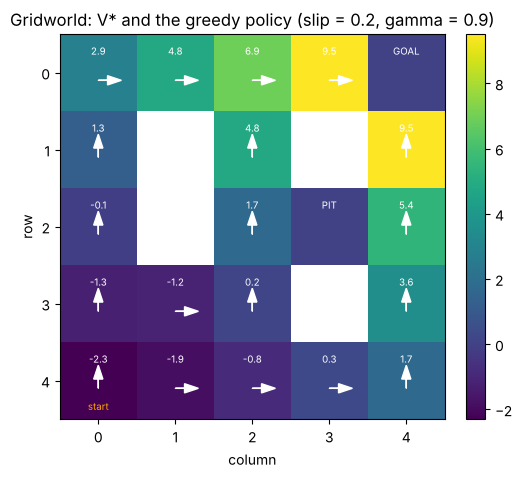

P(end in the pit | start at (4, 0), follow pi*) = 0.023
P(end in the pit | start at (3, 2), follow pi*) = 0.111
P(end in the pit | start at (4, 3), follow pi*) = 0.111
P(end in the pit | start at (2, 4), follow pi*) = 0.111


In [8]:
class GridWorld:
    ACTIONS = np.array([(-1, 0), (0, 1), (1, 0), (0, -1)])      # 0 up, 1 right, 2 down, 3 left
    ARROWS = ["^", ">", "v", "<"]

    def __init__(self, n_rows, n_cols, start, goal, walls=(), pits=(), slip=0.0,
                 step_reward=-1.0, goal_reward=10.0, pit_reward=-10.0, gamma=0.9):
        self.n_rows, self.n_cols = n_rows, n_cols
        self.n_states, self.n_actions = n_rows * n_cols, 4
        self.start, self.goal = self.idx(*start), self.idx(*goal)
        self.walls = {self.idx(*w) for w in walls}
        self.pits = {self.idx(*p) for p in pits}
        self.terminal = {self.goal} | self.pits
        self.slip, self.step_reward, self.goal_reward, self.pit_reward, self.gamma = slip, step_reward, goal_reward, pit_reward, gamma
        self.P, self.R = self._build_model()
        self.cumP = self.P.cumsum(axis=2)                       # for fast sampling

    def idx(self, r, c): return r * self.n_cols + c
    def rc(self, s): return divmod(s, self.n_cols)

    def _move(self, s, a):
        r, c = self.rc(s); dr, dc = self.ACTIONS[a]; r2, c2 = r + dr, c + dc
        if not (0 <= r2 < self.n_rows and 0 <= c2 < self.n_cols) or self.idx(r2, c2) in self.walls:
            return s                                             # bump: stay in place
        return self.idx(r2, c2)

    def _reward(self, s2):
        if s2 == self.goal: return self.goal_reward
        if s2 in self.pits: return self.pit_reward
        return self.step_reward

    def _build_model(self):
        S, A = self.n_states, self.n_actions
        P = np.zeros((S, A, S)); R = np.zeros((S, A))
        for s in range(S):
            if s in self.terminal or s in self.walls:            # absorbing, zero reward
                P[s, :, s] = 1.0; continue
            for a in range(A):
                outcomes = {a: 1.0 - self.slip, (a - 1) % 4: self.slip / 2, (a + 1) % 4: self.slip / 2}
                for a2, prob in outcomes.items():
                    if prob == 0: continue
                    s2 = self._move(s, a2)
                    P[s, a, s2] += prob; R[s, a] += prob * self._reward(s2)
        return P, R

    def step(self, s, a, rng):
        s2 = int(np.searchsorted(self.cumP[s, a], rng.random()))
        return s2, self._reward(s2), s2 in self.terminal

    def show_values(self, V, policy=None, ax=None, title="V*"):
        ax = ax or plt.gca()
        grid = V.reshape(self.n_rows, self.n_cols).copy()
        for w in self.walls: grid[self.rc(w)] = np.nan
        im = ax.imshow(grid, cmap="viridis"); plt.colorbar(im, ax=ax, fraction=0.046)
        for s in range(self.n_states):
            r, c = self.rc(s)
            if s in self.walls: ax.text(c, r, "wall", ha="center", va="center", color="w", fontsize=7); continue
            label = "GOAL" if s == self.goal else ("PIT" if s in self.pits else f"{V[s]:.1f}")
            ax.text(c, r - 0.28, label, ha="center", va="center", color="w", fontsize=7)
            if policy is not None and s not in self.terminal:
                dr, dc = self.ACTIONS[policy[s]]
                ax.arrow(c, r + 0.1, 0.3 * dc, 0.3 * dr, head_width=0.12, color="w", length_includes_head=True)
        sr, sc = self.rc(self.start); ax.text(sc, sr + 0.38, "start", ha="center", color="orange", fontsize=7)
        ax.set_title(title); ax.set_xlabel("column"); ax.set_ylabel("row")
        ax.set_xticks(range(self.n_cols)); ax.set_yticks(range(self.n_rows))

gw = GridWorld(5, 5, start=(4, 0), goal=(0, 4), walls=[(1, 1), (2, 1), (1, 3), (3, 3)], pits=[(2, 3)], slip=0.2, gamma=0.9)
assert np.allclose(gw.P.sum(axis=2), 1.0)
V_star_gw, pi_star_gw, hist_gw = value_iteration(gw.P, gw.R, gw.gamma)
print(f"value iteration: {len(hist_gw) - 1} sweeps to tolerance 1e-10")
print("V* on the grid:\n", V_star_gw.reshape(5, 5))
print("greedy policy:\n", np.array([gw.ARROWS[a] for a in pi_star_gw]).reshape(5, 5))
plt.figure(figsize=(5.5, 5)); gw.show_values(V_star_gw, pi_star_gw, title="Gridworld: V* and the greedy policy (slip = 0.2, gamma = 0.9)"); plt.show()

# how risky is the greedy policy? Probability of ending in the pit, by an absorption-probability solve (Module 18):
# h = P_TT h + P_T,pit over the non-terminal states T, using the transition matrix of pi*
T_states = [s for s in range(gw.n_states) if s not in gw.terminal | gw.walls]
P_pi = gw.P[np.arange(gw.n_states), pi_star_gw]
pit = next(iter(gw.pits))
h_pit = np.linalg.solve(np.eye(len(T_states)) - P_pi[np.ix_(T_states, T_states)], P_pi[T_states, pit])
p_pit = dict(zip(T_states, h_pit))
for cell in [(4, 0), (3, 2), (4, 3), (2, 4)]:
    print(f"P(end in the pit | start at {cell}, follow pi*) = {p_pit[gw.idx(*cell)]:.3f}")

The values fall off with distance from the goal; the start is worth about $-2.3$ because the $+10$ is at least
eight slippery steps away. Three corridors lead to the goal: up the left column and along the top row, which never
passes the pit, and the middle and right-hand columns, each of which passes one cell beside it. The greedy policy
splits the grid between them — from the start it takes the safe left/top route, while cells nearer the middle or
the right accept one risky step because the detour would cost more. The absorption probabilities price that risk:
about $0.11$ of agents starting at $(3, 2)$, $(4, 3)$ or $(2, 4)$ end in the pit (each attempt to pass it slips
sideways into it with probability $0.1$, and a slip into a wall just means trying again: $0.1/0.9$), against about
$0.02$ from the start. The policy is read off as $\arg\max_a Q^*(s, a)$: no search, no simulation, just the model.

Now **policy iteration**: evaluate exactly (a linear solve), improve greedily, repeat until the policy is stable.
We compare the number of iterations of the two methods as $\gamma$ varies.

In [9]:
def policy_iteration(P, R, gamma, max_iter=100):
    S = P.shape[0]; policy = np.zeros(S, dtype=int)
    for n in range(1, max_iter + 1):
        V = policy_evaluation_exact(P, R, policy, gamma)
        Q = q_from_v(P, R, V, gamma)
        greedy = Q.argmax(axis=1)
        # keep the current action where it is already (within rounding) a maximiser -> guaranteed termination
        stable = np.isclose(Q[np.arange(S), policy], Q.max(axis=1))
        new_policy = np.where(stable, policy, greedy)
        if np.array_equal(new_policy, policy):
            return V, policy, n
        policy = new_policy
    return V, policy, max_iter

V_pi_gw, pi_pi_gw, n_pi = policy_iteration(gw.P, gw.R, gw.gamma)
print(f"policy iteration: {n_pi} iterations; agrees with value iteration: "
      f"values {np.allclose(V_pi_gw, V_star_gw)}, policy on non-terminal states "
      f"{np.array_equal(pi_pi_gw[[s for s in range(25) if s not in gw.terminal | gw.walls]], pi_star_gw[[s for s in range(25) if s not in gw.terminal | gw.walls]])}")

def policy_string(env, policy):
    return "".join("." if s in env.terminal | env.walls else env.ARROWS[int(policy[s])] for s in range(env.n_states))

print(f"\n{'gamma':>6s} {'VI sweeps':>10s} {'PI iters':>9s} {'worst-case VI bound':>20s} {'rho':>6s} {'gamma*rho':>10s}   policy (row by row)")
for g in [0.5, 0.8, 0.9, 0.95, 0.99]:
    V_g, pi_g, h = value_iteration(gw.P, gw.R, g, tol=1e-8)
    _, _, n = policy_iteration(gw.P, gw.R, g)
    worst = np.log(np.abs(V_g).max() / 1e-8) / np.log(1 / g)               # sweeps a factor-gamma contraction would need
    P_TT = gw.P[np.arange(gw.n_states), pi_g][np.ix_(T_states, T_states)]  # pi_g's transitions among non-terminal states
    rho = np.abs(np.linalg.eigvals(P_TT)).max()                            # spectral radius < 1: the agent terminates
    print(f"{g:6.2f} {len(h) - 1:10d} {n:9d} {worst:20.0f} {rho:6.3f} {g * rho:10.3f}   {policy_string(gw, pi_g)}")

policy iteration: 4 iterations; agrees with value iteration: values True, policy on non-terminal states True

 gamma  VI sweeps  PI iters  worst-case VI bound    rho  gamma*rho   policy (row by row)
  0.50         22         3                   30  0.913      0.456   >>>>.^.^.^^.<.^^>^.^^>>>^
  0.80         29         5                   93  0.437      0.350   >>>>.^.^.^^.^.^^>^.^^>>>^
  0.90         33         4                  196  0.437      0.394   >>>>.^.^.^^.^.^^>^.^^>>>^
  0.95         35         5                  403  0.437      0.415   >>>>.^.^.^^.^.^^>^.^^>>>^
  0.99         36         6                 2059  0.437      0.433   >>>>.^.^.^^.^.^^>^.^^>>>^


Policy iteration finishes in a handful of iterations whatever $\gamma$ is, each costing a $25 \times 25$ linear
solve, and agrees with value iteration to machine precision. Value iteration's sweep count rises only gently (from
22 to 36) and stays far below the worst-case bound $\ln(\lVert V^*\rVert_\infty/\epsilon)/\ln(1/\gamma)$ — about 2,000 at
$\gamma = 0.99$. The reason is that this task is *episodic*: the goal and the pit are absorbing with value 0, so an
error is carried forward only along paths that have not yet terminated, and the asymptotic factor per sweep is
$\gamma\rho$, where $\rho$ is the spectral radius of the optimal policy's transition matrix among the non-terminal
states — roughly, the per-step probability of not having finished yet. Here $\rho \approx 0.44$, so even at
$\gamma = 0.99$ errors shrink by a factor of about $0.43$ per sweep. (At $\gamma = 0.5$ the policy changes: the
myopic agent at $(2, 2)$ prefers to bump into the wall rather than walk past the pit, a near-self-loop that pushes
$\rho$ up to $0.91$.) In a *continuing* task such as the machine of Section 4, $\rho = 1$ and the factor really is
$\gamma$. For a few thousand states policy iteration's $O(|\mathcal S|^3)$ solve is still fine; beyond that, value
iteration (or a few evaluation sweeps per improvement — *modified* policy iteration) takes over.

**Try it yourself:** set `pit_reward=-50` (keeping `slip=0.2`) and re-run: $(3, 1)$, $(3, 2)$ and $(4, 1)$ switch to the
safe left-column route at a cost of two to four extra steps, while $(4, 2)$ and $(4, 3)$ keep the shorter route past
the pit — for them the risky step lies several moves ahead and is discounted (at $\gamma = 0.99$, $(4, 2)$ detours
too). Then set `slip=0.0`: the start's value rises from $-2.3$ to about $-0.4$, the price of slippery floors.

## 6. Learning without a model: Monte Carlo, TD(0), SARSA and Q-learning

First **prediction**. We simulate 5,000 episodes of the optimal machine policy (vectorised) and estimate
$V^{\pi^*}(\text{Good})$ by averaging returns — the Monte Carlo estimate — against the exact $40$. Then the
classic five-state random walk: an agent starts in the middle, moves left or right at random, and receives $+1$
on exiting to the right. The true values are $1/6, \dots, 5/6$. We compare first-visit Monte Carlo
($V(s) \leftarrow V(s) + \alpha(G - V(s))$) with TD(0) ($V(s) \leftarrow V(s) + \alpha(r + V(s') - V(s))$).

Monte Carlo: V(Good) ~ 40.023 +/- 0.076   exact 40.000   (sd of a single return 5.38; truncation bias < 1.0e-08)


RMS error after 200 episodes: MC(alpha=0.02) 0.043   TD(alpha=0.05) 0.039


RMS error after 200 episodes: MC(alpha=0.04) 0.056   TD(alpha=0.15) 0.072


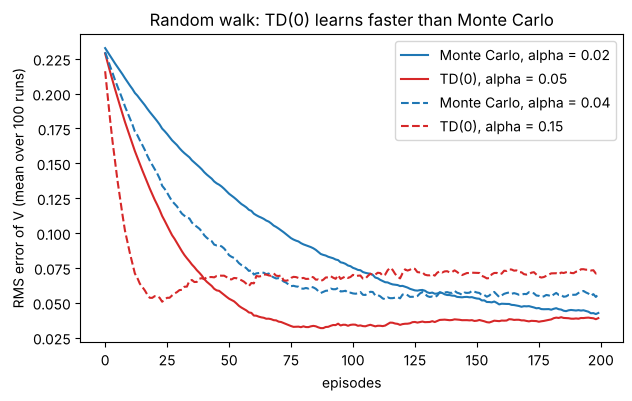

In [10]:
# Monte Carlo estimate of V^pi*(Good) in the machine MDP, 5000 episodes truncated at 100 steps
n_ep, T_max = 5000, 100
cumP_M = P_M.cumsum(axis=2)
s = np.zeros(n_ep, dtype=int); G = np.zeros(n_ep); discount = 1.0
for t in range(T_max):
    a = pi_star[s]
    G += discount * R_M[s, a]                                   # expected reward of (s, a); fine for estimating V
    u = rng.random(n_ep)
    s = (u[:, None] > cumP_M[s, a]).sum(axis=1)                 # sample s' from P(. | s, a)
    discount *= GAMMA_M
print(f"Monte Carlo: V(Good) ~ {G.mean():.3f} +/- {G.std(ddof=1)/np.sqrt(n_ep):.3f}   exact 40.000   "
      f"(sd of a single return {G.std(ddof=1):.2f}; truncation bias < {GAMMA_M**T_max * 10/(1-GAMMA_M):.1e})")

# random walk: states 0..4, exits at -1 (reward 0) and 5 (reward 1); start at 2
def random_walk_episode(rng):
    s = 2; traj = []
    while True:
        s2 = s + (1 if rng.random() < 0.5 else -1)
        r = 1.0 if s2 == 5 else 0.0
        done = s2 < 0 or s2 == 5
        traj.append((s, r, s2, done)); s = s2
        if done: return traj

true_V = np.arange(1, 6) / 6

def mc_vs_td(n_runs=100, n_episodes=200, alpha_mc=0.02, alpha_td=0.1, seed=1):
    rng_w = np.random.default_rng(seed)
    err_mc = np.zeros((n_runs, n_episodes)); err_td = np.zeros((n_runs, n_episodes))
    for run in range(n_runs):
        V_mc = np.full(5, 0.5); V_td = np.full(5, 0.5)
        for ep in range(n_episodes):
            traj = random_walk_episode(rng_w)
            for (s, r, s2, done) in traj:                       # TD(0): one update per step
                target = r + (0.0 if done else V_td[s2])
                V_td[s] += alpha_td * (target - V_td[s])
            G = 0.0; first_visit_return = {}
            for (s, r, s2, done) in reversed(traj):             # MC: returns from the end; earliest visit wins
                G = r + G; first_visit_return[s] = G
            for s, G in first_visit_return.items():
                V_mc[s] += alpha_mc * (G - V_mc[s])
            err_mc[run, ep] = np.sqrt(np.mean((V_mc - true_V) ** 2))
            err_td[run, ep] = np.sqrt(np.mean((V_td - true_V) ** 2))
    return err_mc.mean(axis=0), err_td.mean(axis=0)

for a_mc, a_td, ls in ((0.02, 0.05, "-"), (0.04, 0.15, "--")):
    e_mc, e_td = mc_vs_td(alpha_mc=a_mc, alpha_td=a_td)
    plt.plot(e_mc, "C0", ls=ls, label=f"Monte Carlo, alpha = {a_mc}")
    plt.plot(e_td, "C3", ls=ls, label=f"TD(0), alpha = {a_td}")
    print(f"RMS error after 200 episodes: MC(alpha={a_mc}) {e_mc[-1]:.3f}   TD(alpha={a_td}) {e_td[-1]:.3f}")
plt.xlabel("episodes"); plt.ylabel("RMS error of V (mean over 100 runs)")
plt.title("Random walk: TD(0) learns faster than Monte Carlo"); plt.legend(); plt.show()

In both pairs TD(0) drops faster: its target $r + V(s')$ has the variance of one transition, while a Monte Carlo
return carries the noise of the whole walk. The price is bias — early on, $V(s')$ is wrong — and with a constant
$\alpha$ both methods plateau at a noise floor set by $\alpha$: the dashed, larger-step curves fall fastest and settle
highest, and TD's floor at $\alpha = 0.15$ even ends above Monte Carlo's at $\alpha = 0.04$. Comparing methods fairly
means comparing each at its best step size. Robbins–Monro step sizes ($\sum\alpha_t = \infty$, $\sum\alpha_t^2 < \infty$)
would send both errors to zero.

Now **control** on the cliff-walking task of Sutton and Barto: a $4 \times 12$ grid, start bottom-left, goal
bottom-right, the bottom row in between is a cliff ($-100$ and back to the start); every other move costs $-1$,
$\gamma = 1$. Both SARSA and Q-learning act ε-greedily with $\varepsilon = 0.1$ and differ only in the target:
$Q(s', a')$ for the action actually taken next (SARSA) versus $\max_{a'} Q(s', a')$ (Q-learning).

sarsa      : mean return per episode over the last 100 episodes =  -28.17   greedy path length = 17
q-learning : mean return per episode over the last 100 episodes =  -53.70   greedy path length = 13


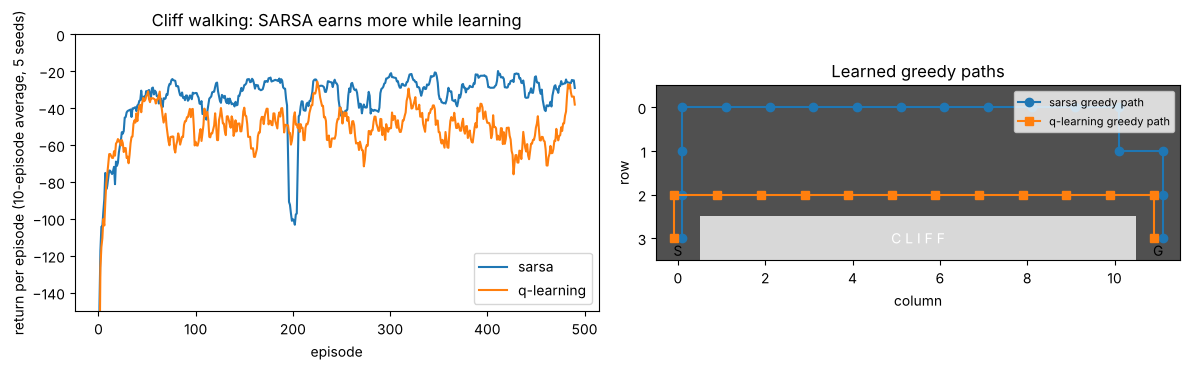

In [11]:
class CliffWalk:
    ACTIONS = np.array([(-1, 0), (0, 1), (1, 0), (0, -1)])
    def __init__(self, n_rows=4, n_cols=12):
        self.n_rows, self.n_cols = n_rows, n_cols
        self.n_states, self.n_actions = n_rows * n_cols, 4
        self.start, self.goal = self.idx(n_rows - 1, 0), self.idx(n_rows - 1, n_cols - 1)
        self.cliff = {self.idx(n_rows - 1, c) for c in range(1, n_cols - 1)}
    def idx(self, r, c): return r * self.n_cols + c
    def rc(self, s): return divmod(s, self.n_cols)
    def step(self, s, a):
        r, c = self.rc(s); dr, dc = self.ACTIONS[a]
        s2 = self.idx(min(max(r + dr, 0), self.n_rows - 1), min(max(c + dc, 0), self.n_cols - 1))
        if s2 in self.cliff: return self.start, -100.0, False
        return s2, -1.0, s2 == self.goal

def td_control(env, method, n_episodes=500, alpha=0.5, gamma=1.0, eps=0.1, seed=0, max_steps=1000):
    rng_c = np.random.default_rng(seed)
    Q = np.zeros((env.n_states, env.n_actions)); episode_return = np.zeros(n_episodes)
    def eps_greedy(s):
        if rng_c.random() < eps: return int(rng_c.integers(env.n_actions))
        return argmax_random_tie(Q[s], rng_c)
    for ep in range(n_episodes):
        s = env.start; a = eps_greedy(s); total = 0.0
        for _ in range(max_steps):
            s2, r, done = env.step(s, a); total += r
            a2 = eps_greedy(s2)
            if method == "q-learning":
                target = r + (0.0 if done else gamma * Q[s2].max())        # off-policy: the greedy continuation
            else:
                target = r + (0.0 if done else gamma * Q[s2, a2])          # on-policy: the continuation actually taken
            Q[s, a] += alpha * (target - Q[s, a])
            s, a = s2, a2
            if done: break
        episode_return[ep] = total
    return Q, episode_return

def greedy_path(env, Q, max_steps=60):
    s = env.start; path = [s]
    for _ in range(max_steps):
        s, _, done = env.step(s, int(Q[s].argmax())); path.append(s)
        if done: break
    return path

cliff = CliffWalk(); curves = {}; Qs = {}
for method in ("sarsa", "q-learning"):
    runs = np.array([td_control(cliff, method, seed=seed)[1] for seed in range(5)])
    curves[method] = runs.mean(axis=0); Qs[method] = td_control(cliff, method, seed=0)[0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
for method, c in curves.items():
    ax1.plot(np.convolve(c, np.ones(10) / 10, mode="valid"), label=method)
    print(f"{method:11s}: mean return per episode over the last 100 episodes = {c[-100:].mean():7.2f}   "
          f"greedy path length = {len(greedy_path(cliff, Qs[method])) - 1}")
ax1.set_ylim(-150, 0); ax1.set_xlabel("episode"); ax1.set_ylabel("return per episode (10-episode average, 5 seeds)")
ax1.set_title("Cliff walking: SARSA earns more while learning"); ax1.legend()
grid = np.zeros((4, 12)); grid[3, 1:11] = -1
ax2.imshow(grid, cmap="Greys", vmin=-1.5, vmax=0.5)
for method, c, m in (("sarsa", "C0", "o"), ("q-learning", "C1", "s")):
    rc = np.array([cliff.rc(s) for s in greedy_path(cliff, Qs[method])])
    ax2.plot(rc[:, 1] + (0.1 if method == "sarsa" else -0.1), rc[:, 0], marker=m, color=c, label=f"{method} greedy path")
ax2.text(5.5, 3, "C L I F F", ha="center", va="center", color="w"); ax2.text(0, 3.4, "S", ha="center"); ax2.text(11, 3.4, "G", ha="center")
ax2.set_xlabel("column"); ax2.set_ylabel("row"); ax2.set_title("Learned greedy paths"); ax2.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

Q-learning learns the optimal (shortest) path along the cliff edge — but while it is still exploring with
$\varepsilon = 0.1$ it keeps falling off, so its return *during training* is far worse. SARSA evaluates the
ε-greedy policy it actually follows, learns that the edge is dangerous for a slipping agent, and takes the
safe upper route: longer, but with higher training returns. Same data, same ε, different target — this is the
on-/off-policy distinction made visible.

**Try it yourself:** make the exploration decay inside `td_control` (e.g. `eps_t = eps / (1 + ep / 20)`) — does SARSA's
greedy path move toward the cliff edge as its own exploration fades? (SARSA converges to the optimal policy only if
exploration vanishes in the limit while every action is still tried infinitely often.) Or set `alpha=0.1` and watch
the learning curves smooth out and slow down.

## 7. Linear function approximation with semi-gradient TD(0)

A 20-state random walk with $\gamma = 1$: exit left gives $-1$, exit right $+1$, so $V(s)$ rises linearly from
$-0.90$ to $+0.90$. We approximate $\hat V(s; w) = w^\top\phi(s)$ with three feature maps — a cubic polynomial in
the normalised position (4 weights), state aggregation into 4 blocks of 5 states (4 weights), and one-hot
features (20 weights, which recovers tabular TD) — using the semi-gradient update

$$w \leftarrow w + \alpha\,[r + \gamma\, w^\top\phi(s') - w^\top\phi(s)]\,\phi(s).$$

polynomial (cubic)       weights: [-0.7423  1.337   0.4535 -0.0244]


aggregation (4 blocks)   weights: [-0.1678 -0.0758  0.0293  0.1916]


one-hot (tabular)        weights: [-0.8996 -0.8219 -0.734  -0.6443 -0.5431 -0.4695 -0.3796 -0.2983 -0.2119
 -0.1057  0.0492  0.1493  0.2548  0.3548  0.4857  0.5871  0.7123  0.7751
  0.8451  0.9264]


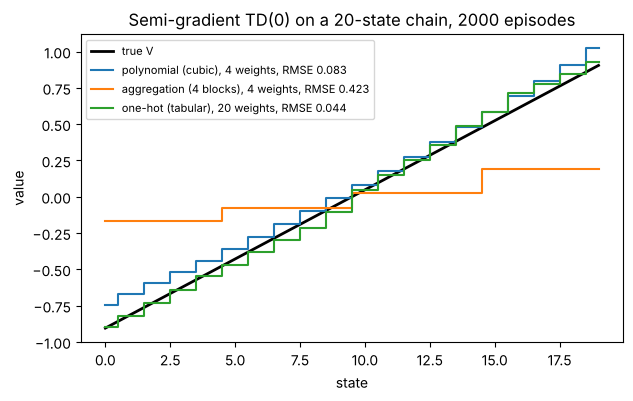

polynomial (cubic)       TD fixed point: RMSE 0.000, w = [-0.905  1.81   0.     0.   ]   best approximation: RMSE 0.000, w = [-0.905  1.81   0.     0.   ]
aggregation (4 blocks)   TD fixed point: RMSE 0.407, w = [-0.206 -0.048  0.048  0.206]   best approximation: RMSE 0.143, w = [-0.651 -0.214  0.214  0.651]
aggregated chain: a walker in the leftmost block exits left with probability 0.033 per step (true chain: 0.5 from state 0)


In [12]:
n_chain = 20
P_chain = np.zeros((n_chain, n_chain)); R_chain = np.zeros(n_chain)
for s in range(n_chain):
    for d, reward in ((-1, -1.0), (1, 1.0)):
        if 0 <= s + d < n_chain: P_chain[s, s + d] += 0.5
        else: R_chain[s] += 0.5 * reward
V_true_chain = np.linalg.solve(np.eye(n_chain) - P_chain, R_chain)        # exact values (gamma = 1, absorbing exits)

def chain_episode(rng):
    s = n_chain // 2; traj = []
    while True:
        s2 = s + (1 if rng.random() < 0.5 else -1)
        if s2 < 0:         traj.append((s, -1.0, None)); return traj
        if s2 >= n_chain:  traj.append((s, +1.0, None)); return traj
        traj.append((s, 0.0, s2)); s = s2

def features(s, kind):
    x = s / (n_chain - 1)
    if kind == "polynomial (cubic)": return np.array([1.0, x, x**2, x**3])
    if kind == "aggregation (4 blocks)": f = np.zeros(4); f[s // 5] = 1.0; return f
    if kind == "one-hot (tabular)": f = np.zeros(n_chain); f[s] = 1.0; return f

def semi_gradient_td0(kind, n_episodes=2000, alpha=0.01, gamma=1.0, seed=0):
    rng_f = np.random.default_rng(seed); w = np.zeros(len(features(0, kind)))
    for _ in range(n_episodes):
        for (s, r, s2) in chain_episode(rng_f):
            phi = features(s, kind)
            target = r + (0.0 if s2 is None else gamma * w @ features(s2, kind))
            w += alpha * (target - w @ phi) * phi                        # gradient of (target - w.phi)^2 wrt w, target held fixed
    return w

plt.plot(V_true_chain, "k-", lw=2, label="true V")
for kind, alpha in (("polynomial (cubic)", 0.01), ("aggregation (4 blocks)", 0.02), ("one-hot (tabular)", 0.05)):
    w = semi_gradient_td0(kind, alpha=alpha)
    V_hat = np.array([w @ features(s, kind) for s in range(n_chain)])
    plt.step(range(n_chain), V_hat, where="mid", label=f"{kind}, {len(w)} weights, RMSE {np.sqrt(np.mean((V_hat - V_true_chain)**2)):.3f}")
    print(f"{kind:24s} weights: {w}")
plt.xlabel("state"); plt.ylabel("value"); plt.title("Semi-gradient TD(0) on a 20-state chain, 2000 episodes"); plt.legend(fontsize=8); plt.show()

# where does semi-gradient TD converge? The TD fixed point solves Phi^T D (R + P Phi w - Phi w) = 0 (gamma = 1 here),
# with D the on-policy state distribution; compare it with the best approximation, the D-weighted projection of V.
start_dist = np.zeros(n_chain); start_dist[n_chain // 2] = 1.0
visits = np.linalg.solve(np.eye(n_chain) - P_chain.T, start_dist)          # expected visits per episode to each state
D = np.diag(visits / visits.sum())
for kind in ("polynomial (cubic)", "aggregation (4 blocks)"):
    Phi = np.array([features(s, kind) for s in range(n_chain)])
    w_td = np.linalg.solve(Phi.T @ D @ (np.eye(n_chain) - P_chain) @ Phi, Phi.T @ D @ R_chain)
    w_best = np.linalg.solve(Phi.T @ D @ Phi, Phi.T @ D @ V_true_chain)
    rmse = lambda w: np.sqrt(np.mean((Phi @ w - V_true_chain) ** 2))
    print(f"{kind:24s} TD fixed point: RMSE {rmse(w_td):.3f}, w = {np.round(w_td, 3) + 0.0}   "
          f"best approximation: RMSE {rmse(w_best):.3f}, w = {np.round(w_best, 3) + 0.0}")
print(f"aggregated chain: a walker in the leftmost block exits left with probability "
      f"{0.5 * D[0, 0] / D.diagonal()[:5].sum():.3f} per step (true chain: 0.5 from state 0)")

The cubic polynomial has the true (linear) value function inside its span, so its TD fixed point is exact; after
2,000 episodes it is within an RMSE of about $0.08$, the rest being slow progress along the nearly collinear
features $x^2$ and $x^3$. Aggregation cannot represent a slope within a block — and TD does not even find the best
staircase: the best approximation (the $D$-weighted projection of $V$) has RMSE $0.14$, while the TD fixed point,
where the learned weights stall, has $0.41$. For state aggregation the TD fixed point is the exact value function of
an *aggregated* chain whose block-to-block transitions are averaged over the states inside each block; in that chain
a walker in the leftmost block exits with probability $0.03$ per step instead of $0.5$ from state 0, so its values
are pulled toward the middle. (The textbook guarantee — TD's error is within a factor $1/(1-\gamma)$ of the best
approximation's — says nothing at $\gamma = 1$; here TD's error is about three times the best.) The one-hot features
are exact but need five times as many weights and more data. Representation *and* bootstrapping set the floor on the
error before learning starts — and each update of the polynomial weights moved *every* state's estimate, which is
both the point of generalisation and the opening for the deadly triad.

## 8. Policy gradients: the score-function estimator, baselines and REINFORCE

For a softmax policy over three arms with deterministic rewards $\mu = (1, 2, 3)$ and scores $\theta = 0$, the
exact gradient is $\nabla_\theta J = \pi \odot (\mu - J) = (-\tfrac13, 0, \tfrac13)$. The REINFORCE estimate from a
single pull $a$ is $(\mu_a - b)(\mathbf e_a - \pi)$: unbiased for **every** baseline $b$, because
$\mathbb E_{a\sim\pi}[\nabla\log\pi(a)] = \nabla\sum_a\pi(a) = 0$, but with a variance that depends strongly on $b$.
Then the baseline at work: REINFORCE on a two-context, three-arm contextual bandit whose rewards are offset by
$+10$, with and without a running-mean baseline.

exact gradient: [-0.3333  0.      0.3333]
baseline b = 0.0: mean of estimates [-0.3295 -0.0004  0.33  ]   total variance 2.884
baseline b = 1.0: mean of estimates [-0.332   0.0004  0.3315]   total variance 0.886
baseline b = 2.0: mean of estimates [-0.3345  0.0013  0.3331]   total variance 0.222
baseline b = 3.0: mean of estimates [-0.3369  0.0022  0.3347]   total variance 0.892


offset  +0.0, no   baseline: P(optimal arm) after 300 steps = 0.742 (sd over 20 seeds 0.051)


offset  +0.0, with baseline: P(optimal arm) after 300 steps = 0.754 (sd over 20 seeds 0.022)


offset +10.0, no   baseline: P(optimal arm) after 300 steps = 0.454 (sd over 20 seeds 0.327)


offset +10.0, with baseline: P(optimal arm) after 300 steps = 0.649 (sd over 20 seeds 0.165)


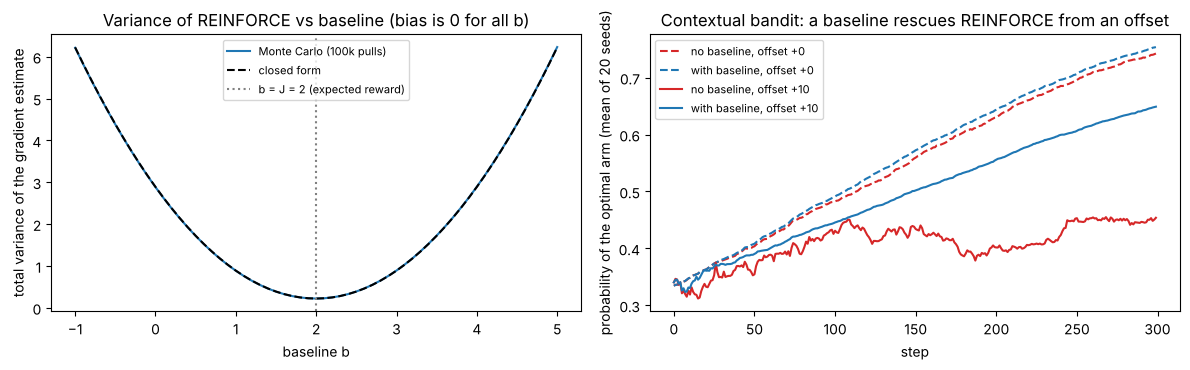

In [13]:
def softmax(z):
    z = z - z.max(); e = np.exp(z); return e / e.sum()

mu = np.array([1.0, 2.0, 3.0]); theta = np.zeros(3); pi = softmax(theta); J = pi @ mu
grad_exact = pi * (mu - J)
print("exact gradient:", grad_exact)

n = 100_000
a = rng.choice(3, size=n, p=pi); score = np.eye(3)[a] - pi            # grad log pi(a) = e_a - pi
baselines = np.linspace(-1, 5, 61); var_mc = []
for b in (0.0, 1.0, 2.0, 3.0):
    est = (mu[a] - b)[:, None] * score
    print(f"baseline b = {b}: mean of estimates {est.mean(axis=0)}   total variance {est.var(axis=0).sum():.3f}")
for b in baselines:
    var_mc.append(((mu[a] - b)[:, None] * score).var(axis=0).sum())
var_exact = [(2/9) * np.sum((mu - b) ** 2) - 2/9 for b in baselines]     # closed form for this bandit

# contextual bandit: 2 contexts x 3 arms, Gaussian rewards around context-dependent means (+ offset)
def contextual_reinforce(n_steps=300, lr=0.05, baseline=False, offset=10.0, seed=0):
    rng_r = np.random.default_rng(seed)
    means = np.array([[0.0, 1.0, 0.5], [1.0, 0.0, 0.5]]) + offset
    theta = np.zeros((2, 3)); b = np.zeros(2); p_opt = np.zeros(n_steps)
    for t in range(n_steps):
        x = int(rng_r.integers(2)); p = softmax(theta[x]); a = int(rng_r.choice(3, p=p))
        r = means[x, a] + 0.5 * rng_r.standard_normal()
        advantage = r - (b[x] if baseline else 0.0)
        theta[x] += lr * advantage * (np.eye(3)[a] - p)                    # REINFORCE step
        if baseline: b[x] += 0.1 * (r - b[x])                              # running mean of rewards per context
        p_opt[t] = np.mean([softmax(theta[c])[means[c].argmax()] for c in range(2)])
    return p_opt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
ax1.plot(baselines, var_mc, label="Monte Carlo (100k pulls)"); ax1.plot(baselines, var_exact, "k--", label="closed form")
ax1.axvline(J, color="gray", ls=":", label="b = J = 2 (expected reward)")
ax1.set_xlabel("baseline b"); ax1.set_ylabel("total variance of the gradient estimate"); ax1.set_title("Variance of REINFORCE vs baseline (bias is 0 for all b)"); ax1.legend(fontsize=8)
for offset, ls in ((0.0, "--"), (10.0, "-")):
    for use_b, c in ((False, "C3"), (True, "C0")):
        runs = np.array([contextual_reinforce(baseline=use_b, offset=offset, seed=s) for s in range(20)])
        ax2.plot(runs.mean(axis=0), color=c, ls=ls, label=f"{'with' if use_b else 'no'} baseline, offset {offset:+.0f}")
        print(f"offset {offset:+5.1f}, {'with' if use_b else 'no  '} baseline: P(optimal arm) after 300 steps = "
              f"{runs[:, -1].mean():.3f} (sd over 20 seeds {runs[:, -1].std():.3f})")
ax2.set_xlabel("step"); ax2.set_ylabel("probability of the optimal arm (mean of 20 seeds)"); ax2.set_title("Contextual bandit: a baseline rescues REINFORCE from an offset"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

The variance curve is a parabola with its minimum near the expected reward — $0.22$ at $b = 2$ against $2.89$ at
$b = 0$, thirteen times smaller for the same expectation. In the contextual bandit, adding $10$ to every reward
changes nothing about which arm is best, yet REINFORCE without a baseline stalls: every action, good or bad,
receives a large positive push, and the policy's progress depends on the lucky difference of two big numbers.
A running-mean baseline removes the offset and restores the signal.

Finally REINFORCE on a deterministic $4 \times 4$ gridworld (start bottom-left, goal top-right, $-1$ per step,
$+10$ at the goal, episodes cut off after 15 steps) with a tabular softmax policy, comparing no baseline with a
learned state-value baseline $\hat V(s)$ (which turns $G_t$ into an advantage estimate). Like most practical
implementations, the code uses the common $\gamma^t$-free variant of the policy gradient: step $t$'s score is weighted by
$G_t - \hat V(s_t)$ rather than by $\gamma^t\,(G_t - \hat V(s_t))$ as the exact gradient of $J = \mathbb{E}[G_0]$ requires. With
$\gamma = 0.99$ and at most 15 steps the two weightings differ by at most 13%; the simplification is exact only for $\gamma = 1$.

no baseline        : mean return over episodes 251-300, per seed: [  4.8   4.7   4.9   4.7   4.8   4.9   4.5 -13.8   4.9   5. ]
                      mean   2.94   median   4.84   seeds stuck below 0: 1


state-value baseline: mean return over episodes 251-300, per seed: [4.7 4.8 4.8 4.4 4.6 4.8 4.5 4.9 4.5 4.6]
                      mean   4.66   median   4.65   seeds stuck below 0: 0


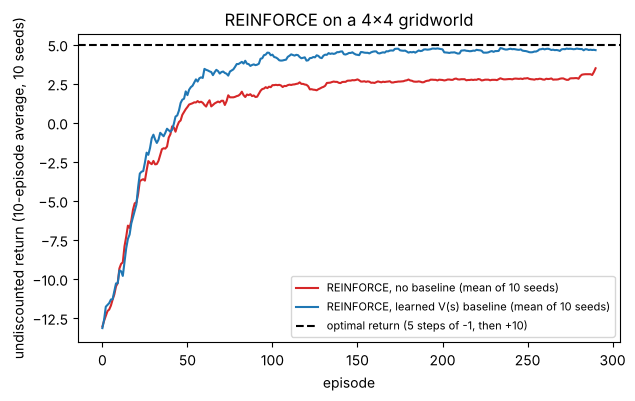

In [14]:
small = GridWorld(4, 4, start=(3, 0), goal=(0, 3), slip=0.0, gamma=0.99)

def reinforce_gridworld(env, n_episodes=300, lr=0.05, gamma=0.99, horizon=15, baseline=None, seed=0):
    rng_g = np.random.default_rng(seed)
    theta = np.zeros((env.n_states, env.n_actions)); V_hat = np.zeros(env.n_states)
    totals = np.zeros(n_episodes)
    for ep in range(n_episodes):
        s = env.start; traj = []
        for t in range(horizon):
            p = softmax(theta[s]); a = int(rng_g.choice(env.n_actions, p=p))
            s2, r, done = env.step(s, a, rng_g); traj.append((s, a, r, p)); s = s2
            if done: break
        G = 0.0; returns = []
        for (_, _, r, _) in reversed(traj):
            G = r + gamma * G; returns.append(G)
        returns = returns[::-1]
        grad = np.zeros_like(theta)
        for (s, a, r, p), G in zip(traj, returns):
            advantage = G - (V_hat[s] if baseline == "state value" else 0.0)
            grad[s] += advantage * (np.eye(env.n_actions)[a] - p)          # gamma^t-free variant (exact: times gamma**t)
        theta += lr * grad                                                 # one gradient step per episode
        for (s, a, r, p), G in zip(traj, returns):
            V_hat[s] += 0.1 * (G - V_hat[s])                               # Monte Carlo critic for the baseline
        totals[ep] = sum(r for (_, _, r, _) in traj)
    return totals, theta

for baseline, c in ((None, "C3"), ("state value", "C0")):
    runs = np.array([reinforce_gridworld(small, baseline=baseline, seed=s)[0] for s in range(10)])
    m = runs.mean(axis=0); finals = runs[:, -50:].mean(axis=1)
    plt.plot(np.convolve(m, np.ones(10) / 10, mode="valid"), color=c, label=f"REINFORCE, {'no baseline' if baseline is None else 'learned V(s) baseline'} (mean of 10 seeds)")
    print(f"{'no baseline        ' if baseline is None else 'state-value baseline'}: mean return over episodes 251-300, per seed: {np.round(finals, 1)}")
    print(f"{'':21s} mean {finals.mean():6.2f}   median {np.median(finals):6.2f}   seeds stuck below 0: {(finals < 0).sum()}")
plt.axhline(5.0, color="k", ls="--", label="optimal return (5 steps of -1, then +10)")
plt.xlabel("episode"); plt.ylabel("undiscounted return (10-episode average, 10 seeds)")
plt.title("REINFORCE on a 4x4 gridworld"); plt.legend(fontsize=8); plt.show()

Nine of the ten no-baseline seeds reach the optimal return of 5 within a couple of hundred episodes — and one
never does: its early returns were all negative, every action it tried was pushed *down*, and the policy
collapsed onto a loop that never reaches the goal. The learned state-value baseline turns returns into
advantages ("better or worse than usual from here"), and all ten seeds converge. Two lessons from Section 10 of
the guide in one plot: the mean curve hides a bimodal outcome, so always look at the per-seed results; and a
baseline matters most when the rewards are all of one sign. The update rule is identical in both cases:
`theta += lr * advantage * (onehot(a) - pi)`, the softmax cross-entropy gradient with the sampled action as the
label and the advantage as the sample weight.

**Try it yourself:** set `lr=0.2` and count the seeds that get stuck. Then add an entropy bonus $c\,H(\pi(\cdot \mid s))$ to
the objective: its gradient with respect to the logits is $-c\,\pi \odot (\log\pi + H)$, so inside the loop over the
trajectory add `H = -(p * np.log(p)).sum(); grad[s] -= 0.01 * p * (np.log(p) + H)` and see whether the stuck seeds recover.

## 9. The optimal KL-regularised policy, DPO and PPO's clip

For a prompt with four candidate responses, a reference policy $\pi_{\text{ref}}$ and rewards $r$, the policy maximising
$\mathbb E_\pi[r] - \beta\,\mathrm{KL}(\pi \,\|\, \pi_{\text{ref}})$ is $\pi^*(y) = \pi_{\text{ref}}(y)\,e^{r(y)/\beta}/Z$ with optimal value
$\beta \log Z$. We verify this by maximising the objective directly over the probability simplex (gradient ascent
on softmax logits), trace the reward–KL frontier as $\beta$ varies, and draw PPO's clipped surrogate.

beta = 2.0: closed form [0.3106 0.3841 0.0942 0.2111]  numeric [0.3106 0.3841 0.0942 0.2111]  max|diff| = 8.3e-17
           objective at pi*: 1.5058 = beta log Z = 1.5058;  at pi_ref: 1.3000;  E[r] = 1.712, KL = 0.103
beta = 1.0: closed form [0.1972 0.4021 0.0363 0.3644]  numeric [0.1972 0.4021 0.0363 0.3644]  max|diff| = 1.5e-16
           objective at pi*: 1.7070 = beta log Z = 1.7070;  at pi_ref: 1.3000;  E[r] = 2.095, KL = 0.388


beta = 0.5: closed form [0.0494 0.2735 0.0033 0.6738]  numeric [0.0494 0.2735 0.0033 0.6738]  max|diff| = 4.0e-11
           objective at pi*: 2.0462 = beta log Z = 2.0462;  at pi_ref: 1.3000;  E[r] = 2.618, KL = 1.143

r(4) - r(1) = 2.000;  beta[log pi*(4)/ref(4) - log pi*(1)/ref(1)] = 2.000


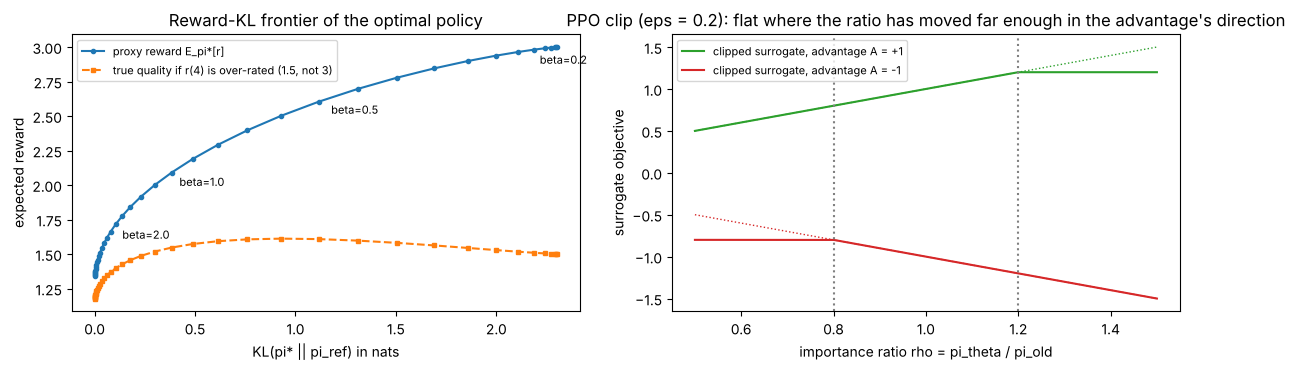

In [15]:
pi_ref = np.array([0.4, 0.3, 0.2, 0.1]); r_model = np.array([1.0, 2.0, 0.0, 3.0])

def kl(p, q): return float(np.sum(p * np.log(p / q)))
def objective(p, beta): return float(p @ r_model - beta * kl(p, pi_ref))

def optimal_policy(beta):
    w = pi_ref * np.exp(r_model / beta); return w / w.sum(), w.sum()

def maximise_numerically(beta, n_steps=8000, lr=1.0):
    z = np.log(pi_ref).copy()                                       # start from the reference
    for _ in range(n_steps):
        q = softmax(z)
        g_q = r_model - beta * (np.log(q / pi_ref) + 1.0)           # d objective / d q
        z += lr * q * (g_q - q @ g_q)                                # chain rule through the softmax
    return softmax(z)

for beta in (2.0, 1.0, 0.5):
    p_star, Z = optimal_policy(beta); p_num = maximise_numerically(beta)
    print(f"beta = {beta}: closed form {p_star}  numeric {p_num}  max|diff| = {np.abs(p_star - p_num).max():.1e}")
    print(f"           objective at pi*: {objective(p_star, beta):.4f} = beta log Z = {beta*np.log(Z):.4f};  "
          f"at pi_ref: {objective(pi_ref, beta):.4f};  E[r] = {p_star @ r_model:.3f}, KL = {kl(p_star, pi_ref):.3f}")

# DPO's identity: reward differences equal beta * differences of log-ratios (log Z cancels)
p_star, _ = optimal_policy(1.0)
print(f"\nr(4) - r(1) = {r_model[3] - r_model[0]:.3f};  beta[log pi*(4)/ref(4) - log pi*(1)/ref(1)] = "
      f"{np.log(p_star[3]/pi_ref[3]) - np.log(p_star[0]/pi_ref[0]):.3f}")

betas = np.logspace(-1, 1.3, 40)
frontier = np.array([(kl(optimal_policy(b)[0], pi_ref), optimal_policy(b)[0] @ r_model) for b in betas])
true_quality = np.array([1.0, 2.0, 0.0, 1.5])                        # suppose the reward model over-rates response 4
true_frontier = np.array([optimal_policy(b)[0] @ true_quality for b in betas])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
ax1.plot(frontier[:, 0], frontier[:, 1], "o-", ms=3, label="proxy reward E_pi*[r]")
ax1.plot(frontier[:, 0], true_frontier, "s--", ms=3, label="true quality if r(4) is over-rated (1.5, not 3)")
for b in (2.0, 1.0, 0.5, 0.2):
    p_b, _ = optimal_policy(b); ax1.annotate(f"beta={b}", (kl(p_b, pi_ref), p_b @ r_model), textcoords="offset points", xytext=(5, -10), fontsize=8)
ax1.set_xlabel("KL(pi* || pi_ref) in nats"); ax1.set_ylabel("expected reward"); ax1.set_title("Reward-KL frontier of the optimal policy"); ax1.legend(fontsize=8)
rho = np.linspace(0.5, 1.5, 300); eps_clip = 0.2
for A, c in ((1.0, "C2"), (-1.0, "C3")):
    ax2.plot(rho, np.minimum(rho * A, np.clip(rho, 1 - eps_clip, 1 + eps_clip) * A), color=c, label=f"clipped surrogate, advantage A = {A:+.0f}")
    ax2.plot(rho, rho * A, color=c, ls=":", lw=1)
ax2.axvline(1 - eps_clip, color="gray", ls=":"); ax2.axvline(1 + eps_clip, color="gray", ls=":")
ax2.set_xlabel("importance ratio rho = pi_theta / pi_old"); ax2.set_ylabel("surrogate objective"); ax2.set_title("PPO clip (eps = 0.2): flat where the ratio has moved far enough in the advantage's direction"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

Gradient ascent over the simplex lands on the Boltzmann re-weighting $\pi_{\text{ref}}\, e^{r/\beta}/Z$ to six decimals,
and the maximal objective equals $\beta\log Z$ — the two facts DPO rests on. The frontier is concave: the first
tenth of a nat of KL buys a lot of reward, the last nat very little. If the reward model over-rates one
response, the *true* quality peaks at a moderate $\beta$ and then falls while the proxy keeps rising — reward
over-optimisation in miniature, and the reason RLHF runs watch the KL to the reference. PPO's clipped surrogate
is flat beyond $1 \pm \epsilon$ *only* on the side the advantage points to; a bad action whose probability has grown
($A < 0$, $\rho > 1.2$) still receives a full gradient pushing it back.

## Summary

- The return $G_t = \sum_k \gamma^k r_{t+k+1}$ defines the objective; $1/(1-\gamma)$ is the horizon the agent effectively cares about.
- Bandits isolate exploration: ε-greedy has linear regret, UCB1 (Hoeffding bonus) and Thompson sampling (posterior draws) have logarithmic regret and need no tuning of an exploration schedule.
- For a fixed policy the Bellman equation is linear and $V^\pi = (I - \gamma P^\pi)^{-1}R^\pi$; the optimality operator is a $\gamma$-contraction, so value iteration converges geometrically and a stopping rule yields an error bound.
- Policy iteration converges in a few expensive iterations, value iteration in many cheap sweeps whose number grows like $1/(1-\gamma)$.
- Monte Carlo is unbiased and noisy; TD(0) bootstraps, trading bias for variance and winning on finite data. SARSA (on-policy) and Q-learning (off-policy) differ only in the target — and therefore in what they learn.
- Semi-gradient TD with linear features converges on-policy to a fixed point whose quality the representation sets; bootstrapping + off-policy + approximation is the deadly triad.
- The score-function trick gives $\nabla J = \mathbb E[\sum_t \gamma^t\,\nabla\log\pi(a_t \mid s_t)(G_t - b(s_t))]$ for any baseline $b$ (practical code, including ours, often drops the $\gamma^t$); a good baseline cuts variance by an order of magnitude at zero bias.
- The optimal KL-regularised policy is $\pi_{\text{ref}}\,e^{r/\beta}/Z$ (DPO's closed form); PPO's clip removes the incentive to move the policy too far in one update.

**Next:** open `exercises.ipynb` and work through the self-checked problems; the solutions notebook has reference implementations.